In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable. Using CPU.")

PyTorch version: 2.11.0+cu130
Selected device: cuda
GPU: Tesla T4


In [ ]:
# Import libraries
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from PIL import Image, ImageFilter, ImageEnhance
from google.colab import files
from torchvision import transforms
from torchvision.models import vgg19, VGG19_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Libraries imported successfully!")

Libraries imported successfully!


Upload your CONTENT photo first.


Saving content.png to content (1).png
Upload your STYLE painting next.


Saving art.png to art (2).png


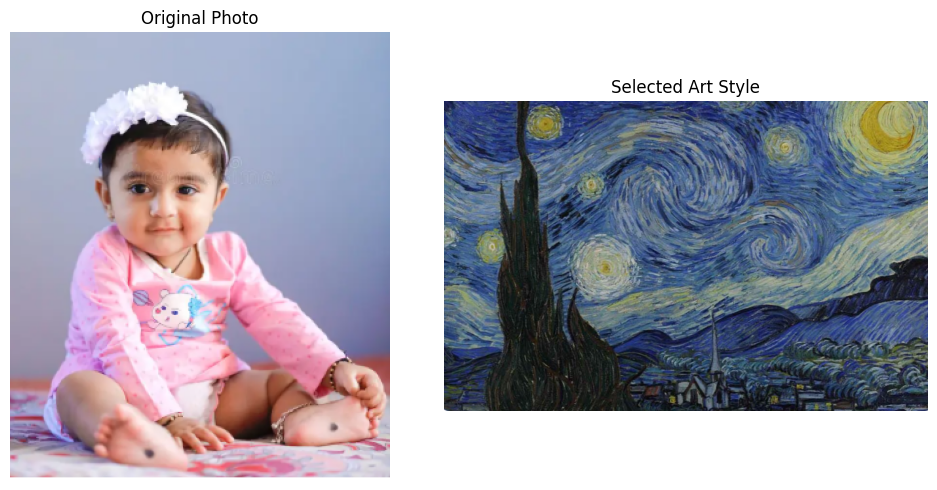

In [ ]:
# Upload your photograph and style image
print("Upload your CONTENT photo first.")
content_upload = files.upload()
content_path = next(iter(content_upload))

print("Upload your STYLE painting next.")
style_upload = files.upload()
style_path = next(iter(style_upload))

content_original = Image.open(content_path).convert("RGB")
style_original = Image.open(style_path).convert("RGB")

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(content_original)
ax[0].set_title("Original Photo")
ax[0].axis("off")

ax[1].imshow(style_original)
ax[1].set_title("Selected Art Style")
ax[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Load the pretrained VGG19 model
weights = VGG19_Weights.DEFAULT

vgg = vgg19(weights=weights).features.to(device).eval()

for param in vgg.parameters():
    param.requires_grad_(False)

print("Pretrained VGG19 loaded successfully!")

Pretrained VGG19 loaded successfully!


In [ ]:
# Create the image-processing functions
def load_image(image, size):
    image = image.copy()
    image.thumbnail((size, size), Image.Resampling.LANCZOS)

    tensor = transforms.ToTensor()(image)
    return tensor.unsqueeze(0).to(device)


def show_tensor(tensor, title="Image"):
    image = tensor.detach().cpu().squeeze(0)
    image = image.clamp(0, 1).permute(1, 2, 0).numpy()

    plt.figure(figsize=(7, 7))
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")
    plt.show()


# VGG19 feature-layer indices
STYLE_LAYERS = [0, 5, 10, 19, 28]
CONTENT_LAYER = 21




def extract_features(image):
    outputs = {}
    x = image

    required_layers = set(STYLE_LAYERS + [CONTENT_LAYER])

    for index, layer in enumerate(vgg):
        x = layer(x)

        if index in required_layers:
            outputs[index] = x

        # Stop only after collecting every required layer
        if index >= max(required_layers):
            break

    return outputs

print("Feature extraction function corrected!")


def gram_matrix(feature):
    batch, channels, height, width = feature.shape

    feature = feature.view(channels, height * width)
    gram = feature @ feature.T

    return gram / (channels * height * width)

Feature extraction function corrected!


In [ ]:

test_image = load_image(content_original, 160)

with torch.no_grad():
    test_features = extract_features(test_image)

print("Available feature layers:", list(test_features.keys()))

assert CONTENT_LAYER in test_features
assert all(layer in test_features for layer in STYLE_LAYERS)

print("Success! All required feature layers are available.")


Available feature layers: [0, 5, 10, 19, 21, 28]
Success! All required feature layers are available.


In [ ]:
# Implement the baseline model
# Baseline: Standard Neural Style Transfer (NST)


def neural_style_transfer(
    content_pil,
    style_pil,
    image_size=160,
    steps=60,
    style_weight=100000,
    content_weight=1.0
):
    # Load input images
    content = load_image(content_pil, image_size)
    style = load_image(style_pil, image_size)

    # Extract reference features
    with torch.no_grad():
        content_features = extract_features(content)
        style_features = extract_features(style)

        # Use the same layer constants as extract_features()
        content_target = content_features[CONTENT_LAYER].detach()

        style_targets = {}
        for layer in STYLE_LAYERS:
            if layer not in style_features:
                raise ValueError(
                    f"Style layer {layer} was not extracted. "
                    f"Available layers: {list(style_features.keys())}"
                )

            style_targets[layer] = gram_matrix(
                style_features[layer]
            ).detach()

    # Start with the original content image
    output = content.clone().detach().requires_grad_(True)

    optimizer = optim.Adam([output], lr=0.02)

    for step in range(steps):
        optimizer.zero_grad()

        output_features = extract_features(output)

        content_loss = F.mse_loss(
            output_features[CONTENT_LAYER],
            content_target
        )

        style_loss = torch.zeros((), device=device)

        for layer in STYLE_LAYERS:
            generated_gram = gram_matrix(
                output_features[layer]
            )

            style_loss += F.mse_loss(
                generated_gram,
                style_targets[layer]
            )

        total_loss = (
            content_weight * content_loss
            + style_weight * style_loss
        )

        total_loss.backward()
        optimizer.step()

        with torch.no_grad():
            output.clamp_(0, 1)

        if (step + 1) % 20 == 0:
            print(
                f"Step {step+1}/{steps} | "
                f"Content loss: {content_loss.item():.5f} | "
                f"Style loss: {style_loss.item():.6f}"
            )

    return output.detach()


In [ ]:
print("Style layers:", STYLE_LAYERS)
print("Content layer:", CONTENT_LAYER)

test_image = load_image(content_original, 160)

with torch.no_grad():
    test_features = extract_features(test_image)

print("Available feature layers:", list(test_features.keys()))

assert CONTENT_LAYER in test_features
assert all(layer in test_features for layer in STYLE_LAYERS)

print("All required layers are available!")

Style layers: [0, 5, 10, 19, 28]
Content layer: 21
Available feature layers: [0, 5, 10, 19, 21, 28]
All required layers are available!


Step 20/60 | Content loss: 4.44727 | Style loss: 0.000033
Step 40/60 | Content loss: 3.78904 | Style loss: 0.000024
Step 60/60 | Content loss: 3.43297 | Style loss: 0.000020


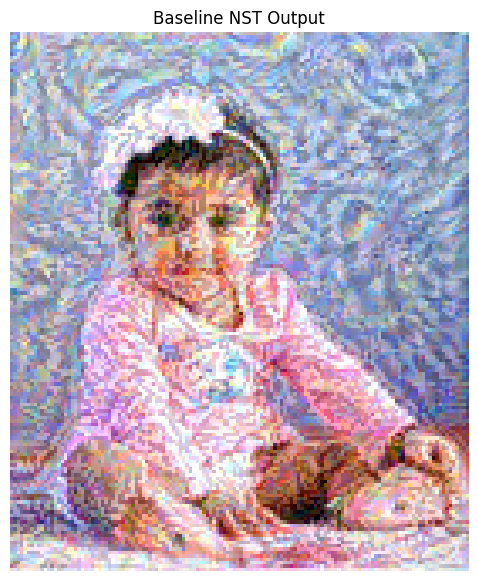

Baseline processing time: 1.15 seconds


In [ ]:
start = time.time()

baseline_output = neural_style_transfer(
    content_original,
    style_original,
    image_size=160,
    steps=60,
    style_weight=100000,
    content_weight=1.0
)

baseline_time = time.time() - start

show_tensor(baseline_output, "Baseline NST Output")

print(f"Baseline processing time: {baseline_time:.2f} seconds")

Starting Main VGG19 Neural Style Transfer...
Style strength: Balanced
Image resolution: 256
Optimization steps: 120
Step 20/120 | Content loss: 2.64776 | Style loss: 0.000016
Step 40/120 | Content loss: 2.07376 | Style loss: 0.000011
Step 60/120 | Content loss: 1.78106 | Style loss: 0.000009
Step 80/120 | Content loss: 1.59357 | Style loss: 0.000008
Step 100/120 | Content loss: 1.48685 | Style loss: 0.000007
Step 120/120 | Content loss: 1.47401 | Style loss: 0.000008

Main model completed successfully!
Processing time: 4.52 seconds


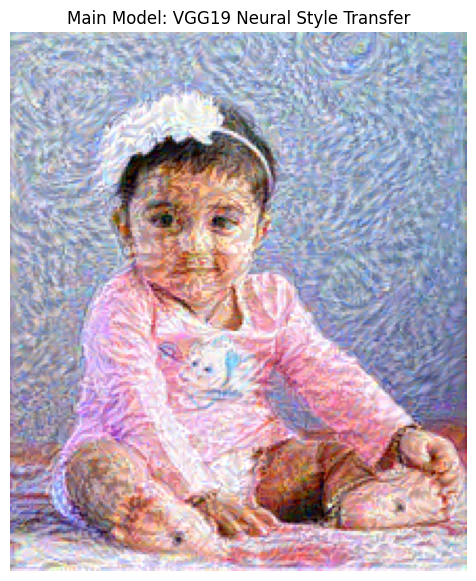

In [ ]:
# Run the main VGG19 model
import time

# Main model configuration
MAIN_SIZE = 256
MAIN_STEPS = 120
MAIN_STYLE_WEIGHT = 100000
MAIN_CONTENT_WEIGHT = 1.0

print("Starting Main VGG19 Neural Style Transfer...")
print("Style strength: Balanced")
print("Image resolution:", MAIN_SIZE)
print("Optimization steps:", MAIN_STEPS)

start = time.time()

main_output = neural_style_transfer(
    content_pil=content_original,
    style_pil=style_original,
    image_size=MAIN_SIZE,
    steps=MAIN_STEPS,
    style_weight=MAIN_STYLE_WEIGHT,
    content_weight=MAIN_CONTENT_WEIGHT
)

main_time = time.time() - start

print("\nMain model completed successfully!")
print(f"Processing time: {main_time:.2f} seconds")

show_tensor(main_output, "Main Model: VGG19 Neural Style Transfer")


In [ ]:
# Add adjustable sharpening

from PIL import Image, ImageEnhance

def tensor_to_pil(tensor):
    image = tensor.detach().cpu().squeeze(0)
    image = image.clamp(0, 1).permute(1, 2, 0).numpy()

    image = (image * 255).round().astype("uint8")
    return Image.fromarray(image)


def enhance_artwork(
    image,
    sharpness=1.4,
    contrast=1.05
):
    # Sharpen edges
    result = ImageEnhance.Sharpness(image).enhance(sharpness)

    # Slightly improve contrast
    result = ImageEnhance.Contrast(result).enhance(contrast)

    return result


# Convert model output to a normal image
main_pil = tensor_to_pil(main_output)

# Enhancement settings
SHARPNESS = 1.4
CONTRAST = 1.05

enhanced_artwork = enhance_artwork(
    main_pil,
    sharpness=SHARPNESS,
    contrast=CONTRAST
)

print("Sharpening and contrast enhancement completed!")


Sharpening and contrast enhancement completed!


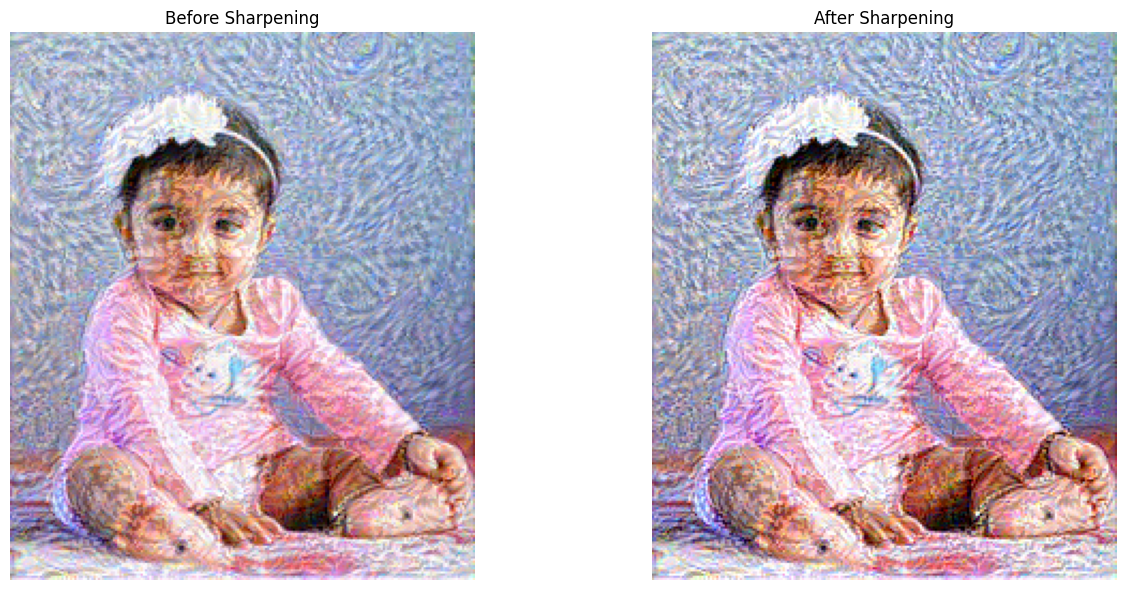

In [ ]:
# Compare before and after enhancement

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(main_pil)
plt.title("Before Sharpening")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(enhanced_artwork)
plt.title("After Sharpening")
plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from google.colab import files
import os

output_path = "/content/ai_art_studio_vgg19_balanced.png"

enhanced_artwork.save(
    output_path,
    format="PNG"
)

print("Final artwork saved!")
print("File path:", output_path)
print("Image dimensions:", enhanced_artwork.size)

files.download(output_path)


Final artwork saved!
File path: /content/ai_art_studio_vgg19_balanced.png
Image dimensions: (217, 256)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Compare baseline and main models

import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Baseline NST",
        "Main VGG19 NST"
    ],
    "Resolution (max side)": [
        160,
        MAIN_SIZE
    ],
    "Optimization Steps": [
        60,
        MAIN_STEPS
    ],
    "Processing Time (seconds)": [
        round(baseline_time, 2),
        round(main_time, 2)
    ]
})

display(comparison)


,Model,Resolution (max side),Optimization Steps,Processing Time (seconds)
0,Baseline NST,160,60,1.15
1,Main VGG19 NST,256,120,4.52


In [ ]:

import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

def evaluate_nst(output_tensor, image_size):
    content = load_image(content_original, image_size)
    style = load_image(style_original, image_size)

    with torch.no_grad():
        content_features = extract_features(content)
        style_features = extract_features(style)
        output_features = extract_features(output_tensor)

        # Content preservation loss (lower is better)
        content_loss = F.mse_loss(
            output_features[CONTENT_LAYER],
            content_features[CONTENT_LAYER]
        ).item()

        # Artistic style matching loss (lower is better)
        style_loss = 0.0

        for layer in STYLE_LAYERS:
            output_gram = gram_matrix(output_features[layer])
            target_gram = gram_matrix(
                style_features[layer]
            )

            style_loss += F.mse_loss(
                output_gram, target_gram
            ).item()

    return content_loss, style_loss


baseline_content_loss, baseline_style_loss = evaluate_nst(
    baseline_output, 160
)

main_content_loss, main_style_loss = evaluate_nst(
    main_output, MAIN_SIZE
)

print("Evaluation completed!")


Evaluation completed!


In [ ]:
# Performance table
results = pd.DataFrame({
    "Model": ["Baseline NST", "Main VGG19 NST"],
    "Content Loss": [
        baseline_content_loss,
        main_content_loss
    ],
    "Style Loss": [
        baseline_style_loss,
        main_style_loss
    ],
    "Processing Time (seconds)": [
        baseline_time,
        main_time
    ]
})

display(results.round(6))


,Model,Content Loss,Style Loss,Processing Time (seconds)
0,Baseline NST,3.389371,0.000021,1.150461
1,Main VGG19 NST,1.472636,0.000008,4.518776


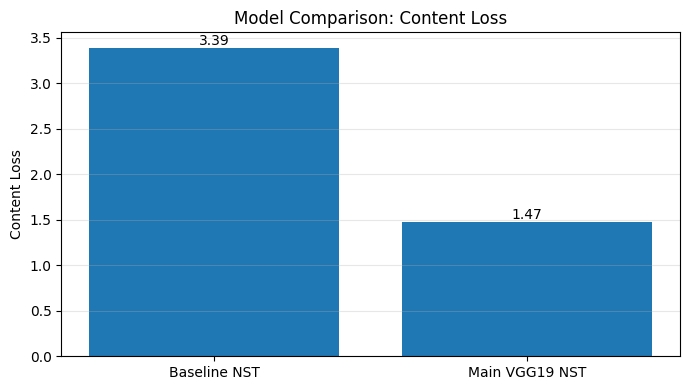

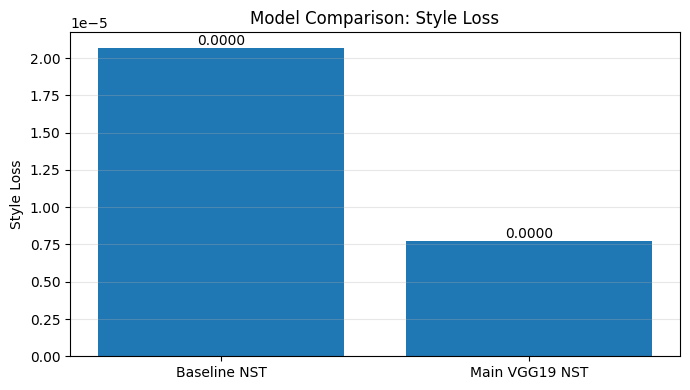

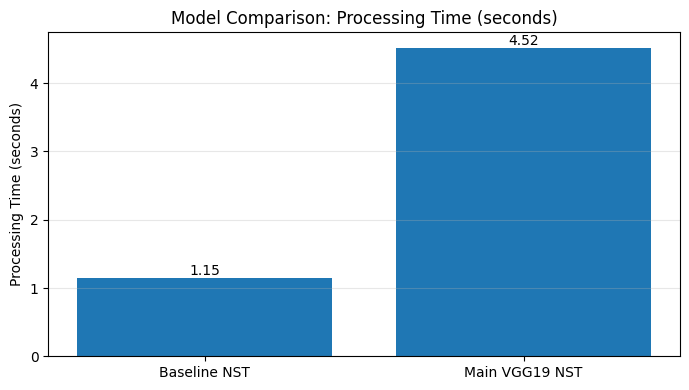

In [ ]:
# Visualize model performance
model_names = ["Baseline NST", "Main VGG19 NST"]

metrics = [
    ("Content Loss", [baseline_content_loss, main_content_loss]),
    ("Style Loss", [baseline_style_loss, main_style_loss]),
    ("Processing Time (seconds)", [baseline_time, main_time])
]

for title, values in metrics:
    plt.figure(figsize=(7, 4))
    bars = plt.bar(model_names, values)

    plt.title(f"Model Comparison: {title}")
    plt.ylabel(title)
    plt.grid(axis="y", alpha=0.3)

    for bar, value in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.4f}" if value < 1 else f"{value:.2f}",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.show()


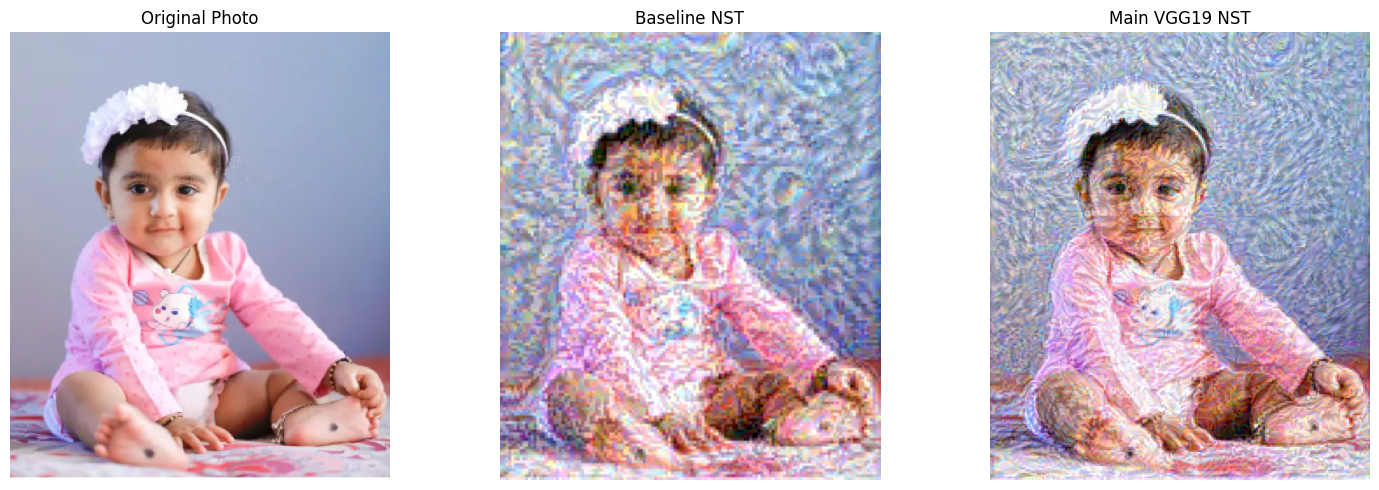

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(content_original)
axes[0].set_title("Original Photo")
axes[0].axis("off")

axes[1].imshow(tensor_to_pil(baseline_output))
axes[1].set_title("Baseline NST")
axes[1].axis("off")

axes[2].imshow(tensor_to_pil(main_output))
axes[2].set_title("Main VGG19 NST")
axes[2].axis("off")

plt.tight_layout()
plt.show()


In [ ]:

print("=" * 45)
print("AI ART STUDIO - PERFORMANCE SUMMARY")
print("=" * 45)

if main_time < baseline_time:
    print("Speed: Main model ran faster.")
elif main_time > baseline_time:
    print("Speed: Baseline model ran faster.")
else:
    print("Speed: Both models took equal time.")

if main_content_loss < baseline_content_loss:
    print("Content features: Main model has lower loss.")
else:
    print("Content features: Baseline has lower or equal loss.")

if main_style_loss < baseline_style_loss:
    print("Style features: Main model has lower loss.")
else:
    print("Style features: Baseline has lower or equal loss.")

print("\nNote: Lower feature loss is not a guarantee")
print("of better-looking artwork.")
print("=" * 45)


AI ART STUDIO - PERFORMANCE SUMMARY
Speed: Baseline model ran faster.
Content features: Main model has lower loss.
Style features: Main model has lower loss.

Note: Lower feature loss is not a guarantee
of better-looking artwork.
